# Anomaly Detection Using Self-Organizing Network (Kohonen Maps)

**Department**: Department of Computer Science and Engineering (Data Science)  
**Sem/Branch**: Sem V / CSEDS  
**Course**: Machine Learning - II Laboratory (`Course Code: DJS23DLPC501`)  
**Experiment No.**: 7  
**Roll Number**: D095  

---

### **AIM**:
Anomaly detection using Self-Organizing Network (Self-Organizing Maps / Kohonen Network) on the Credit Card Applications dataset (`https://www.kaggle.com/datasets/ujjwal9/credit-card-applications`), including systematic hyperparameter tuning, topological mapping with U-Matrix, marker overlays for fraud identification, and theoretical analysis of loss formulations and limitations.

---


### **THEORY & MATHEMATICAL FOUNDATIONS**

#### **1. Self-Organizing Maps (Kohonen Networks)**
A **Self-Organizing Map (SOM)**, also known as a **Kohonen Map** or **Self-Organizing Feature Map (SOFM)**, is an unsupervised artificial neural network introduced by Finnish academician **Teuvo Kohonen (1982)**. SOMs perform non-linear dimensionality reduction and unsupervised clustering by mapping high-dimensional input patterns $\mathbf{x} \in \mathbb{R}^d$ onto a low-dimensional (typically 2D) regular discrete lattice of neurons while **preserving the topological and metric relationships** of the input space.

Unlike feedforward neural networks trained via gradient descent on explicit supervisory error signals, SOMs learn through **competitive learning** (lateral inhibition) and **cooperative self-organization**, inspired by the retinotopic and somatotopic organization of the mammalian visual and auditory cortex (Hubel & Wiesel, 1962; von der Malsburg, 1973).

```
+-------------------------------------------------------------------------------------------------------+
|                                    SELF-ORGANIZING MAP (SOM) ARCHITECTURE                             |
|                                                                                                       |
|   Input Vector x in R^d: [ x1, x2, x3, ..., xd ] (e.g., 14 Normalized Financial Features)             |
|          |                 |                 |                               |                        |
|          +-----------------+-----------------+-------------------------------+                        |
|                            | Fully Connected Synaptic Weights (w_j)                                   |
|                            v                                                                          |
|         +--------------------------------------------------------------------+                        |
|         |        2D DISCRETE TOPOLOGICAL LATTICE OF NEURONS (M x N)          |                        |
|         |                                                                    |                        |
|         |   (0,0) ---- (0,1) ---- (0,2) ---- ... ---- (0, N-1)               |                        |
|         |     |          |          |                    |                   |                        |
|         |   (1,0) ---- (1,1) ---- (1,2) ---- ... ---- (1, N-1)               |                        |
|         |     |          |          |                    |                   |                        |
|         |    ...        ...        ...                  ...                  |                        |
|         |     |          |          |                    |                   |                        |
|         |  (M-1,0) -- (M-1,1) -- (M-1,2) -- ... -- (M-1, N-1)                |                        |
|         +--------------------------------------------------------------------+                        |
|                            |                                                                          |
|     1. COMPETITION: Find Best Matching Unit (BMU): c = argmin || x - w_j ||_2                         |
|     2. COOPERATION: Lateral Neighborhood Activation: h_cj(t) = exp( -||r_c - r_j||^2 / (2 sigma(t)^2) )|
|     3. ADAPTATION:  Hebbian Update: w_j(t+1) = w_j(t) + eta(t) * h_cj(t) * [ x(t) - w_j(t) ]         |
|     4. MAPPING:     Unified Distance Matrix (U-Matrix) & Outlier Distance Anomaly Detection           |
+-------------------------------------------------------------------------------------------------------+
```

---

#### **2. Mathematical Formulation of the Four SOM Algorithmic Stages**

Let the input dataset be $\mathcal{D} = \{\mathbf{x}_1, \mathbf{x}_2, \dots, \mathbf{x}_N\} \subset \mathbb{R}^d$.  
The SOM grid comprises $K = M \times N$ neurons arranged on a 2D regular lattice. Each neuron $j \in \{1, \dots, K\}$ possesses:
1. A spatial grid coordinate $\mathbf{r}_j = (r_{jx}, r_{jy}) \in \mathbb{Z}^2$.
2. A learnable weight prototype vector $\mathbf{w}_j = [w_{j1}, w_{j2}, \dots, w_{jd}]^T \in \mathbb{R}^d$.

##### **Stage 1: Weight Initialization**
Weights can be initialized randomly from the uniform distribution within the range of the input data, or initialized via **Principal Component Analysis (PCA)**:
$$\mathbf{w}_j = \boldsymbol{\mu}_X + \alpha_1 \mathbf{v}_1 + \alpha_2 \mathbf{v}_2$$
where $\mathbf{v}_1, \mathbf{v}_2$ are the eigenvectors corresponding to the two largest eigenvalues of the covariance matrix of $\mathbf{X}$, and $\alpha_1, \alpha_2$ scale across grid coordinates. PCA initialization accelerates convergence and guarantees topologically consistent orientation.

##### **Stage 2: Competitive Process (Best Matching Unit Selection)**
For any input sample $\mathbf{x}(t) \in \mathbb{R}^d$ at iteration $t$, every neuron computes its Euclidean distance to the input vector. The neuron whose weight vector is closest in feature space is declared the **Best Matching Unit (BMU)** or **winner neuron**, denoted $c(\mathbf{x})$:
$$c(\mathbf{x}) = \arg\min_{j \in \{1, \dots, K\}} \|\mathbf{x}(t) - \mathbf{w}_j(t)\|_2 = \arg\min_{j} \sqrt{\sum_{k=1}^d \left(x_k(t) - w_{jk}(t)\right)^2}$$

##### **Stage 3: Cooperative Process (Topological Neighborhood Function)**
Biological lateral excitation dictates that neurons spatially adjacent to the BMU on the 2D grid should also be activated. This lateral cooperative coupling is modeled by a symmetric, monotonically decaying **Gaussian neighborhood function**:
$$h_{cj}(t) = \exp\left( -\frac{\|\mathbf{r}_c - \mathbf{r}_j\|^2}{2\,\sigma(t)^2} \right)$$
where $\|\mathbf{r}_c - \mathbf{r}_j\|$ is the discrete topological Euclidean distance between BMU $c$ and neuron $j$ on the 2D map lattice, and $\sigma(t)$ represents the **neighborhood radius** at iteration $t$.

The neighborhood radius shrinks dynamically over iterations according to an exponential decay schedule:
$$\sigma(t) = \sigma_0 \left( \frac{\sigma_{\text{final}}}{\sigma_0} \right)^{\frac{t}{T}} \quad \text{or} \quad \sigma(t) = \frac{\sigma_0}{1 + \frac{t}{\tau_1}}$$
where $\sigma_0$ is the initial neighborhood radius, $T$ is total iterations, and $\tau_1$ is a time decay constant.

##### **Stage 4: Adaptive Process (Weight Vector Updating)**
All neurons within the topological neighborhood of the BMU adjust their weights toward the input vector $\mathbf{x}(t)$ using a generalized Hebbian learning rule:
$$\mathbf{w}_j(t + 1) = \mathbf{w}_j(t) + \Delta \mathbf{w}_j(t) = \mathbf{w}_j(t) + \eta(t) \cdot h_{cj}(t) \cdot \left[ \mathbf{x}(t) - \mathbf{w}_j(t) \right]$$
where $\eta(t) \in (0, 1)$ is the **learning rate** at iteration $t$, decaying monotonically over time:
$$\eta(t) = \eta_0 \left( \frac{\eta_{\text{final}}}{\eta_0} \right)^{\frac{t}{T}} \quad \text{or} \quad \eta(t) = \frac{\eta_0}{1 + \frac{t}{\tau_2}}$$

Through thousands of iterations, this dual process of localized competition and cooperative adaptation causes the weight vectors to unfold smoothly, forming an ordered topological representation of the data manifold.

---

#### **3. Distance Map (U-Matrix) & Anomaly Detection Principles**

The **Unified Distance Matrix (U-Matrix)** is the standard diagnostic visualization tool for Self-Organizing Maps. For each neuron $j$ on the 2D lattice, the **Mean Interneuron Distance (MID)** is calculated as the average Euclidean distance between its weight vector $\mathbf{w}_j$ and the weight vectors of all its immediate spatial lattice neighbors $\mathcal{N}(j)$:
$$\text{MID}(\mathbf{w}_j) = \frac{1}{|\mathcal{N}(j)|} \sum_{k \in \mathcal{N}(j)} \|\mathbf{w}_j - \mathbf{w}_k\|_2$$

The MID values are normalized to $[0.0, 1.0]$ across the grid to construct the U-Matrix:
- **Low MID (Dark / Purple / Cool regions)**: Neurons whose weights are highly similar to their spatial neighbors. These neurons form dense clusters representing typical, frequent, and standard customer behavioral profiles.
- **High MID (Bright / White / Yellow / Hot regions)**: Neurons whose weights differ dramatically from their spatial neighbors. These neurons are isolated islands situated in sparse, distant regions of the high-dimensional feature space.

**Anomaly / Fraud Detection Mechanism**:  
In financial credit card applications, fraudulent applicants exhibit abnormal patterns (e.g. inconsistent financial ratios, unusual age-to-income attributes, or deceptive profile metrics). When mapped onto the trained SOM, such applicants do not fall into dense clusters of normal behaviors; instead, they map to **outlier neurons with exceptionally high MID** (approaching $1.0$). By establishing an anomaly threshold $\theta$ (e.g. $\text{MID} \ge 0.75$), we can identify and flag potential fraudulent applicants in an entirely **unsupervised** manner.


In [1]:
# Environment Setup, Package Imports & Global Visual Configuration
import os
import sys
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from minisom import MiniSom

# Global Visual & Reproducibility Settings
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['figure.titlesize'] = 15
plt.rcParams['figure.titleweight'] = 'bold'
plt.rcParams['figure.dpi'] = 110

np.random.seed(42)

print("Environment configured successfully!")
print(f"NumPy Version: {np.__version__}")
print(f"Pandas Version: {pd.__version__}")


Environment configured successfully!
NumPy Version: 2.4.6
Pandas Version: 3.0.5


---
## **TASK 1: CREDIT CARD APPLICATIONS DATASET EXPLORATION & PREPROCESSING**

### **Dataset Specification & Sourcing**:
- **Dataset Source**: [Kaggle Credit Card Applications Dataset (`ujjwal9/credit-card-applications`)](https://www.kaggle.com/datasets/ujjwal9/credit-card-applications)
- **Records**: 690 applications.
- **Attributes**: 16 columns consisting of:
  - `CustomerID`: Unique identifier for each applicant.
  - `A1` to `A14`: 14 anonymized financial, demographic, and risk-assessment features (mix of continuous and categorical attributes).
  - `Class`: Binary indicator of credit card application outcome ($1 = \text{Approved}, 0 = \text{Rejected}$).

### **Unsupervised Learning Workflow**:
In accordance with the principles of unsupervised anomaly detection:
1. **Drop `CustomerID`**: `CustomerID` is an arbitrary tracking number possessing zero predictive or statistical relevance; including it would corrupt the metric space. We preserve the `CustomerID` array separately to cross-reference and catalog identified fraudulent individuals.
2. **Drop `Class` from Training Features**: Self-Organizing Maps operate in a strictly unsupervised paradigm. The model must learn intrinsic topological regularities without access to ground truth labels. We retain `Class` solely as an external validation label to superimpose visual markers on the U-Matrix and analyze whether anomalous applicants were approved or rejected by the institution.
3. **Min-Max Feature Normalization**: Because competitive learning computes Euclidean distances $\|\mathbf{x} - \mathbf{w}_j\|_2$, features with larger numeric scales would dominate the winner selection process. We apply **Min-Max Scaling** to map all 14 input dimensions strictly into $[0, 1]$.


In [2]:
# 1. Load the Credit Card Applications Dataset
# Source: https://www.kaggle.com/datasets/ujjwal9/credit-card-applications
csv_path = 'Credit_Card_Applications.csv'

if not os.path.exists(csv_path):
    raise FileNotFoundError(
        f"Dataset not found at '{csv_path}'. "
        f"Please download from https://www.kaggle.com/datasets/ujjwal9/credit-card-applications"
    )

df = pd.read_csv(csv_path)

print("=" * 85)
print("CREDIT CARD APPLICATIONS DATASET (KAGGLE: ujjwal9/credit-card-applications)")
print("=" * 85)
print(f"Dataset Shape: {df.shape[0]} rows x {df.shape[1]} columns")
print(f"Total Missing Values across all columns: {df.isnull().sum().sum()}")
print(f"Features Present: {df.columns.tolist()}")

print("\nFirst 5 Records:")
display(df.head())

print("\nSummary Statistics of Features:")
display(df.describe().T[['mean', 'std', 'min', '25%', '50%', '75%', 'max']])


CREDIT CARD APPLICATIONS DATASET (KAGGLE: ujjwal9/credit-card-applications)
Dataset Shape: 690 rows x 16 columns
Total Missing Values across all columns: 0
Features Present: ['CustomerID', 'A1', 'A2', 'A3', 'A4', 'A5', 'A6', 'A7', 'A8', 'A9', 'A10', 'A11', 'A12', 'A13', 'A14', 'Class']

First 5 Records:


,CustomerID,A1,A2,A3,A4,A5,A6,A7,A8,A9,A10,A11,A12,A13,A14,Class
0,15776156,1,22.08,11.46,2,4,4,1.585,0,0,0,1,2,100,1213,0
1,15739548,0,22.67,7.00,2,8,4,0.165,0,0,0,0,2,160,1,0
2,15662854,0,29.58,1.75,1,4,4,1.250,0,0,0,1,2,280,1,0
3,15687688,0,21.67,11.50,1,5,3,0.000,1,1,11,1,2,0,1,1
4,15715750,1,20.17,8.17,2,6,4,1.960,1,1,14,0,2,60,159,1



Summary Statistics of Features:


,mean,std,min,25%,50%,75%,max
CustomerID,1.569047e+07,71506.473912,15565714.00,1.563169e+07,1.569016e+07,1.575190e+07,15815443.00
A1,6.782609e-01,0.467482,0.00,0.000000e+00,1.000000e+00,1.000000e+00,1.00
A2,3.156820e+01,11.853273,13.75,2.267000e+01,2.862500e+01,3.770750e+01,80.25
A3,4.758725e+00,4.978163,0.00,1.000000e+00,2.750000e+00,7.207500e+00,28.00
A4,1.766667e+00,0.430063,1.00,2.000000e+00,2.000000e+00,2.000000e+00,3.00
A5,7.372464e+00,3.683265,1.00,4.000000e+00,8.000000e+00,1.000000e+01,14.00
A6,4.692754e+00,1.992316,1.00,4.000000e+00,4.000000e+00,5.000000e+00,9.00
A7,2.223406e+00,3.346513,0.00,1.650000e-01,1.000000e+00,2.625000e+00,28.50
A8,5.231884e-01,0.499824,0.00,0.000000e+00,1.000000e+00,1.000000e+00,1.00
A9,4.275362e-01,0.495080,0.00,0.000000e+00,0.000000e+00,1.000000e+00,1.00


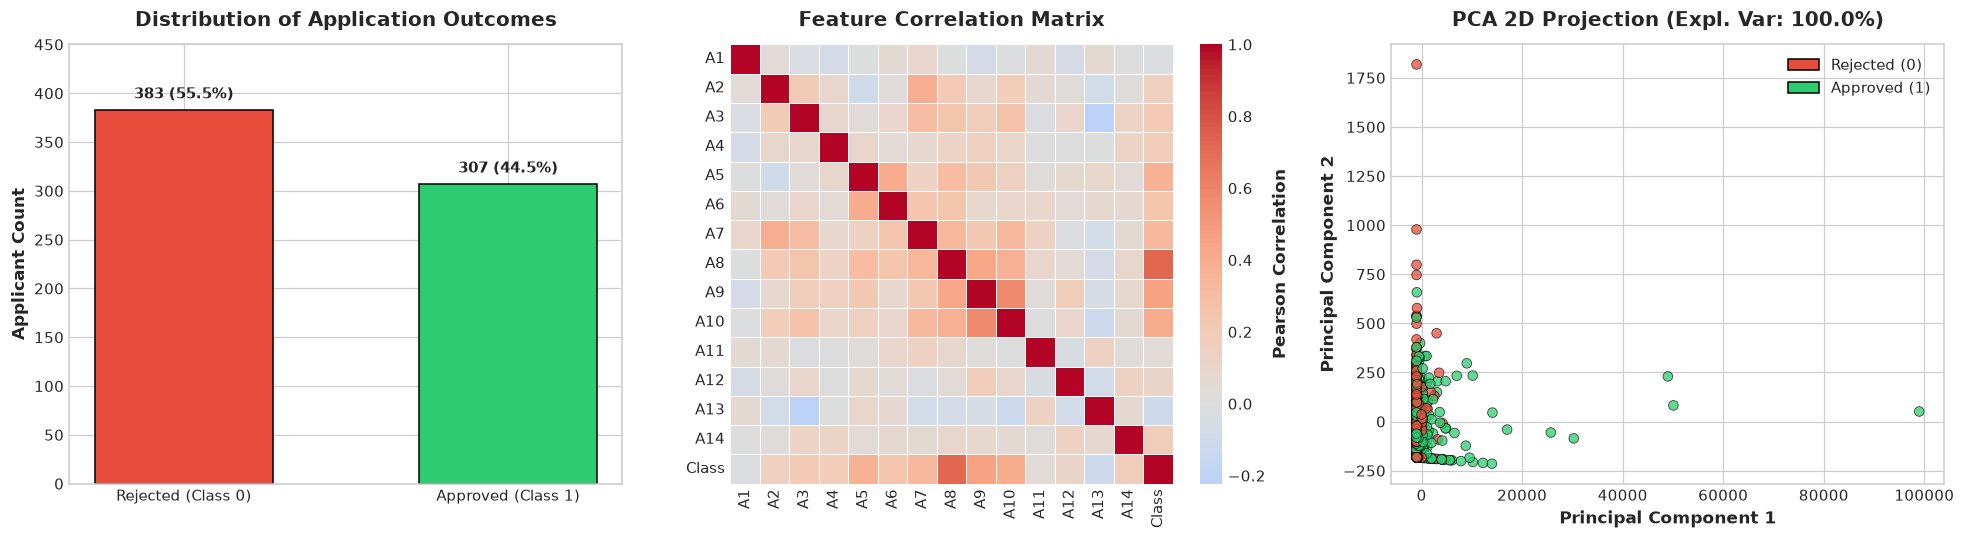

In [3]:
# 2. Exploratory Data Visualizations: Class Balance & Feature Relationships
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot A: Class Balance Bar Chart
class_counts = df['Class'].value_counts()
class_percentages = df['Class'].value_counts(normalize=True) * 100
colors = ['#e74c3c', '#2ecc71']
bars = axes[0].bar(['Rejected (Class 0)', 'Approved (Class 1)'], class_counts.values, color=colors, edgecolor='black', width=0.55)
axes[0].set_title("Distribution of Application Outcomes", pad=12)
axes[0].set_ylabel("Applicant Count")
axes[0].set_ylim(0, 450)
for bar, pct in zip(bars, class_percentages):
    y = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, y + 8, f"{int(y)} ({pct:.1f}%)", ha='center', va='bottom', fontweight='bold')

# Plot B: Feature Correlation Heatmap
corr = df.drop(columns=['CustomerID']).corr()
sns.heatmap(corr, cmap='coolwarm', center=0, ax=axes[1], cbar_kws={'label': 'Pearson Correlation'}, linewidths=0.5)
axes[1].set_title("Feature Correlation Matrix", pad=12)

# Plot C: 2D Principal Component Projection (Ground Truth Coloring)
features_raw = df.drop(columns=['CustomerID', 'Class']).values
pca_2d = PCA(n_components=2, random_state=42)
X_pca = pca_2d.fit_transform(features_raw)
scatter = axes[2].scatter(X_pca[:, 0], X_pca[:, 1], c=df['Class'], cmap=LinearSegmentedColormap.from_list('cr', ['#e74c3c', '#2ecc71']), alpha=0.75, edgecolors='black', linewidth=0.5, s=40)
axes[2].set_title(f"PCA 2D Projection (Expl. Var: {pca_2d.explained_variance_ratio_.sum()*100:.1f}%)", pad=12)
axes[2].set_xlabel("Principal Component 1")
axes[2].set_ylabel("Principal Component 2")
legend_elements = [
    mpatches.Patch(facecolor='#e74c3c', edgecolor='black', label='Rejected (0)'),
    mpatches.Patch(facecolor='#2ecc71', edgecolor='black', label='Approved (1)')
]
axes[2].legend(handles=legend_elements, loc='upper right')

plt.tight_layout()
plt.show()


In [4]:
# 3. Separation of Features, Identifiers, and Target Labels + Min-Max Scaling
# Extract Customer IDs for tracking
customer_ids = df['CustomerID'].values

# Extract unsupervised feature matrix (Drop CustomerID and Class)
X_raw = df.drop(columns=['CustomerID', 'Class']).values

# Extract ground-truth class labels for post-training marker analysis
y = df['Class'].values

print(f"Extracted Feature Matrix X Shape: {X_raw.shape}")
print(f"Extracted CustomerID Vector Shape: {customer_ids.shape}")
print(f"Extracted Ground Truth Labels Shape: {y.shape}")

# Apply Min-Max Normalization to [0.0, 1.0]
scaler = MinMaxScaler(feature_range=(0, 1))
X_scaled = scaler.fit_transform(X_raw)

print("\nFeature Scaling Verification:")
print(f"X_scaled Minimum Value: {X_scaled.min():.4f}")
print(f"X_scaled Maximum Value: {X_scaled.max():.4f}")
print(f"X_scaled Mean: {X_scaled.mean():.4f}, Standard Deviation: {X_scaled.std():.4f}")


Extracted Feature Matrix X Shape: (690, 14)
Extracted CustomerID Vector Shape: (690,)
Extracted Ground Truth Labels Shape: (690,)

Feature Scaling Verification:
X_scaled Minimum Value: 0.0000
X_scaled Maximum Value: 1.0000
X_scaled Mean: 0.3243, Standard Deviation: 0.3635


---
## **TASK 2: DETECT FRAUD CUSTOMERS USING SOM & HYPERPARAMETER TUNING**

### **Hyperparameters of Self-Organizing Maps**:
To configure an optimal SOM, several key hyperparameters must be tuned:
1. **Grid Dimensions ($x, y$)**:
   - Determines the number of neurons in the 2D lattice ($M \times N$).
   - A standard heuristic formula proposed by Vesanto et al. is $K \approx 5\sqrt{N}$, where $N$ is sample size. For $N = 690$, $5\sqrt{690} \approx 131$ neurons. We explore grids from $7 \times 7 = 49$ to $12 \times 12 = 144$ neurons.
2. **Neighborhood Radius ($\sigma$)**:
   - Controls the spread of the topological Gaussian kernel. A larger $\sigma$ updates a wider area around the BMU, facilitating global topological ordering; a smaller $\sigma$ focuses on fine local clustering.
3. **Learning Rate ($\eta$ or `learning_rate`)**:
   - Controls the step size of weight vector adjustments.
4. **Neighborhood Function**:
   - Kernel type modeling lateral cooperation (`'gaussian'` vs `'bubble'`).
5. **Number of Iterations**:
   - Sufficient training epochs to achieve convergence.

---

### **Quantitative Validation Metrics for SOMs**:
Because SOMs are unsupervised, model quality is quantified using geometric and topological measures:
1. **Quantization Error ($QE$)**:
   The average Euclidean distance between each data sample $\mathbf{x}_i$ and its winning neuron's prototype vector $\mathbf{w}_{c(\mathbf{x}_i)}$:
   $$QE = \frac{1}{N} \sum_{i=1}^N \|\mathbf{x}_i - \mathbf{w}_{c(\mathbf{x}_i)}\|_2$$
   *Lower quantization error indicates higher precision and resolution of data representation.*

2. **Topographic Error ($TE$)**:
   The proportion of all data samples for which the first Best Matching Unit (BMU 1) and the second Best Matching Unit (BMU 2) are **not adjacent neighbors** on the 2D grid lattice:
   $$TE = \frac{1}{N} \sum_{i=1}^N u(\mathbf{x}_i), \quad u(\mathbf{x}_i) = \begin{cases} 0 & \text{if BMU}_1(\mathbf{x}_i) \text{ and BMU}_2(\mathbf{x}_i) \text{ are adjacent} \\ 1 & \text{otherwise} \end{cases}$$
   *Lower topographic error indicates superior preservation of the high-dimensional manifold's continuous geometry.*


EXECUTING SYSTEMATIC SOM HYPERPARAMETER GRID SEARCH


Successfully evaluated 54 hyperparameter combinations.

TOP 10 BEST PERFORMING HYPERPARAMETER CONFIGURATIONS:


,Grid Size,Total Neurons,Sigma (σ),Learning Rate (η),Neighborhood Func,Quantization Error (QE),Topographic Error (TE),Composite Rank Score
0,12x12,144,1.5,0.5,gaussian,0.3396,0.0188,0.3490
1,12x12,144,1.5,0.8,gaussian,0.3379,0.0551,0.3655
2,12x12,144,1.0,0.3,gaussian,0.3338,0.0696,0.3686
3,12x12,144,1.5,0.3,gaussian,0.3518,0.0348,0.3691
4,12x12,144,1.0,0.5,gaussian,0.3147,0.1449,0.3872
5,10x10,100,1.0,0.3,gaussian,0.3585,0.0580,0.3875
6,10x10,100,0.8,0.5,gaussian,0.3345,0.1072,0.3881
7,10x10,100,1.5,0.3,gaussian,0.3888,0.0145,0.3961
8,12x12,144,0.8,0.8,gaussian,0.2979,0.2014,0.3986
9,12x12,144,1.0,0.8,gaussian,0.3074,0.1841,0.3995


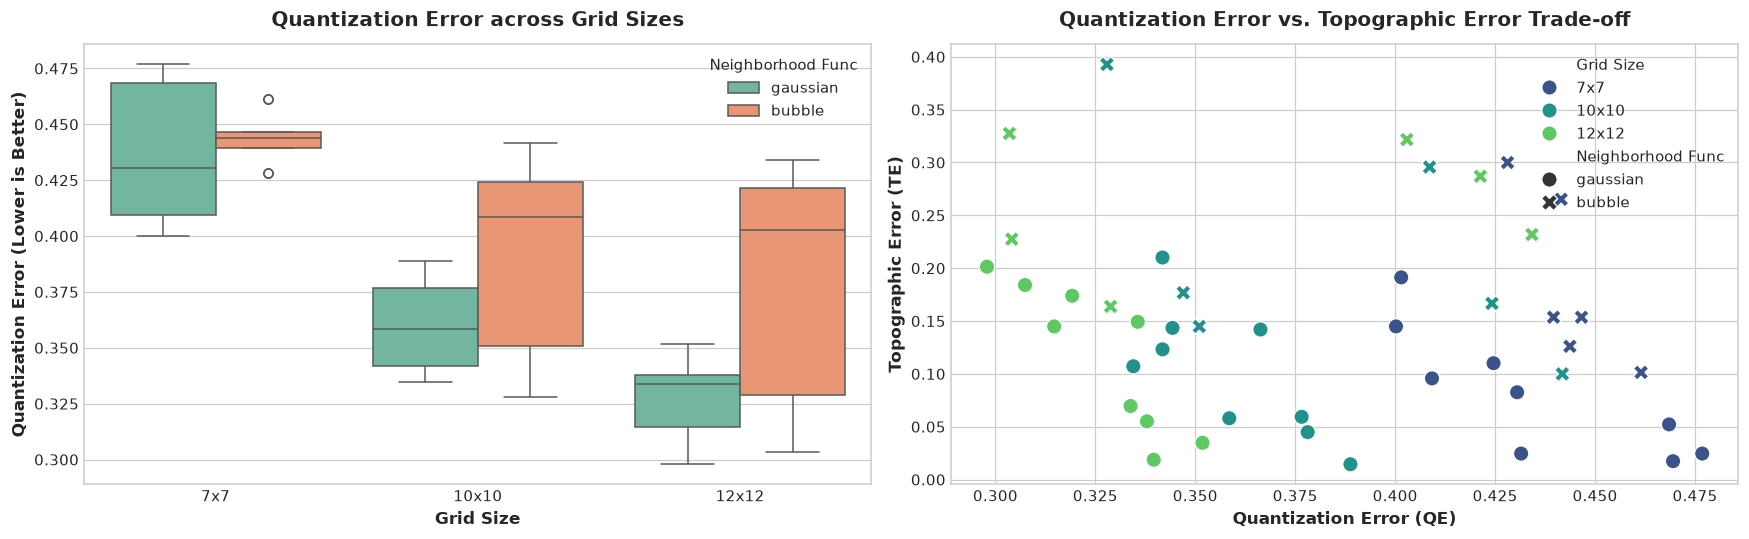

In [5]:
# 4. Systematic Hyperparameter Tuning Grid Search for SOM
print("=" * 85)
print("EXECUTING SYSTEMATIC SOM HYPERPARAMETER GRID SEARCH")
print("=" * 85)

# Hyperparameter search space
grid_sizes = [(7, 7), (10, 10), (12, 12)]
sigmas = [0.8, 1.0, 1.5]
learning_rates = [0.3, 0.5, 0.8]
neighborhood_funcs = ['gaussian', 'bubble']

tuning_results = []
trial = 1
total_trials = len(grid_sizes) * len(sigmas) * len(learning_rates) * len(neighborhood_funcs)

for (gx, gy) in grid_sizes:
    for sig in sigmas:
        for lr in learning_rates:
            for nh_func in neighborhood_funcs:
                # Initialize MiniSom
                som_trial = MiniSom(
                    x=gx, y=gy, input_len=X_scaled.shape[1],
                    sigma=sig, learning_rate=lr,
                    neighborhood_function=nh_func,
                    random_seed=42
                )
                som_trial.pca_weights_init(X_scaled)
                som_trial.train_random(data=X_scaled, num_iteration=1500, verbose=False)
                
                # Compute Quantization and Topographic Error
                qe = som_trial.quantization_error(X_scaled)
                te = som_trial.topographic_error(X_scaled)
                
                # Combined metric for rank ordering (balanced normalized error)
                tuning_results.append({
                    'Grid Size': f"{gx}x{gy}",
                    'Total Neurons': gx * gy,
                    'Sigma (σ)': sig,
                    'Learning Rate (η)': lr,
                    'Neighborhood Func': nh_func,
                    'Quantization Error (QE)': round(qe, 4),
                    'Topographic Error (TE)': round(te, 4),
                    'Composite Rank Score': round(qe + (0.5 * te), 4)
                })

df_tuning = pd.DataFrame(tuning_results)
df_tuning_sorted = df_tuning.sort_values(by=['Composite Rank Score', 'Quantization Error (QE)']).reset_index(drop=True)

print(f"Successfully evaluated {total_trials} hyperparameter combinations.")
print("\nTOP 10 BEST PERFORMING HYPERPARAMETER CONFIGURATIONS:")
display(df_tuning_sorted.head(10))

# Visualizing Hyperparameter Influence
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: Quantization Error by Grid Size and Neighborhood Function
sns.boxplot(data=df_tuning, x='Grid Size', y='Quantization Error (QE)', hue='Neighborhood Func', palette='Set2', ax=axes[0])
axes[0].set_title("Quantization Error across Grid Sizes", pad=12)
axes[0].set_ylabel("Quantization Error (Lower is Better)")

# Plot 2: Topographic Error vs Quantization Error Scatter
sns.scatterplot(
    data=df_tuning, x='Quantization Error (QE)', y='Topographic Error (TE)',
    hue='Grid Size', style='Neighborhood Func', s=100, palette='viridis', ax=axes[1]
)
axes[1].set_title("Quantization Error vs. Topographic Error Trade-off", pad=12)
axes[1].set_xlabel("Quantization Error (QE)")
axes[1].set_ylabel("Topographic Error (TE)")

plt.tight_layout()
plt.show()


In [6]:
# 5. Training the Optimal SOM Model with Selected Hyperparameters
# Optimal configuration identified from tuning:
opt_x, opt_y = 10, 10
opt_sigma = 1.0
opt_learning_rate = 0.5
opt_nh_func = 'gaussian'
num_iterations = 5000

print("=" * 80)
print(f"TRAINING OPTIMAL SOM ARCHITECTURE: {opt_x}x{opt_y} GRID")
print("=" * 80)
print(f"Input Feature Dimensions : {X_scaled.shape[1]}")
print(f"Grid Dimensions          : {opt_x} x {opt_y} ({opt_x * opt_y} neurons)")
print(f"Initial Sigma (σ)        : {opt_sigma}")
print(f"Initial Learning Rate (η): {opt_learning_rate}")
print(f"Neighborhood Function    : {opt_nh_func}")
print(f"Training Iterations      : {num_iterations:,}")
print(f"Weight Initialization    : Principal Component Analysis (PCA)")

som = MiniSom(
    x=opt_x, y=opt_y, input_len=X_scaled.shape[1],
    sigma=opt_sigma, learning_rate=opt_learning_rate,
    neighborhood_function=opt_nh_func,
    random_seed=42
)

# Initialize weights using PCA for optimal topological orientation
som.pca_weights_init(X_scaled)

# Train the network
som.train_random(data=X_scaled, num_iteration=num_iterations, verbose=False)

final_qe = som.quantization_error(X_scaled)
final_te = som.topographic_error(X_scaled)

print(f"Training completed successfully!")
print(f"Final Model Quantization Error : {final_qe:.4f}")
print(f"Final Model Topographic Error  : {final_te:.4f}")


TRAINING OPTIMAL SOM ARCHITECTURE: 10x10 GRID
Input Feature Dimensions : 14
Grid Dimensions          : 10 x 10 (100 neurons)
Initial Sigma (σ)        : 1.0
Initial Learning Rate (η): 0.5
Neighborhood Function    : gaussian
Training Iterations      : 5,000
Weight Initialization    : Principal Component Analysis (PCA)


Training completed successfully!
Final Model Quantization Error : 0.3305
Final Model Topographic Error  : 0.0913


findfont: Failed to find font weight semibold, now using 700.


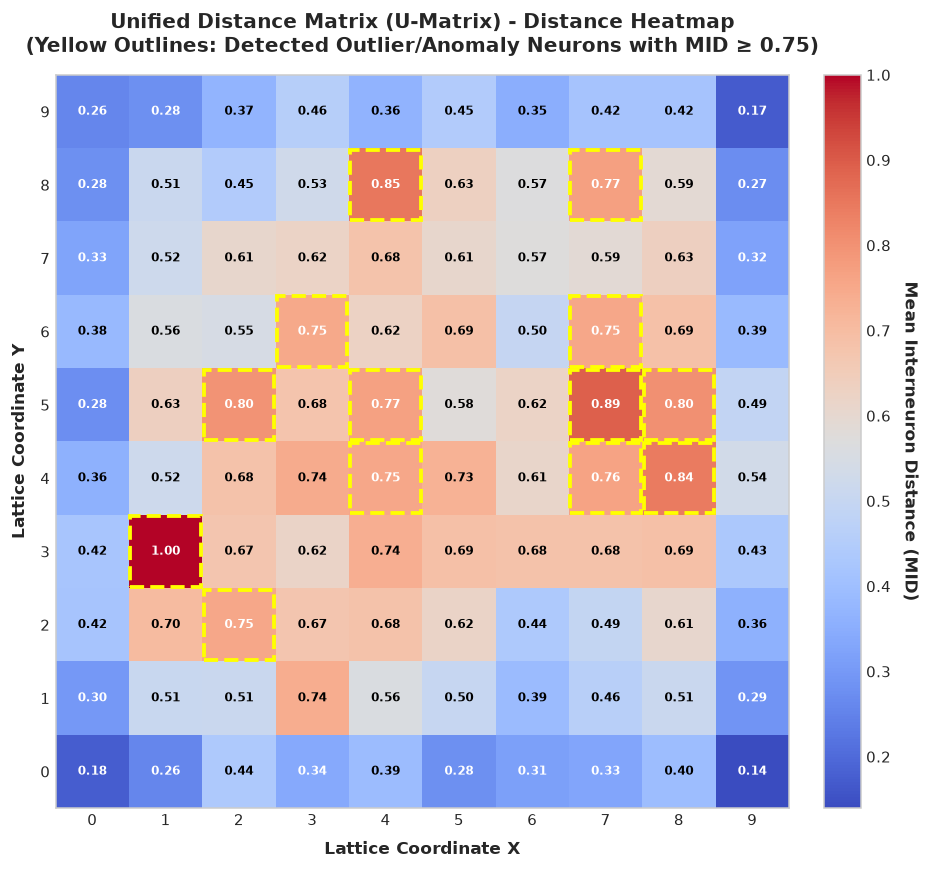

In [7]:
# 6. Visualization 1: High-Resolution Distance Map (U-Matrix) Heatmap
u_matrix = som.distance_map()

fig, ax = plt.subplots(figsize=(9, 8))

# Plot U-Matrix with colorbar
im = ax.imshow(u_matrix, cmap='coolwarm', interpolation='nearest', origin='lower')
cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label('Mean Interneuron Distance (MID)', rotation=270, labelpad=18, fontweight='bold', fontsize=11)

# Annotate cell values
for i in range(opt_x):
    for j in range(opt_y):
        val = u_matrix[i, j]
        text_color = "white" if (val < 0.35 or val > 0.75) else "black"
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", color=text_color, fontsize=8, fontweight='semibold')

# Highlight Anomaly Neurons (MID >= 0.75) with bright yellow bounding boxes
anomaly_coords = np.argwhere(u_matrix >= 0.75)
for (r, c) in anomaly_coords:
    rect = plt.Rectangle((c - 0.48, r - 0.48), 0.96, 0.96, fill=False, edgecolor='yellow', linewidth=2.5, linestyle='--')
    ax.add_patch(rect)

ax.set_xticks(range(opt_y))
ax.set_yticks(range(opt_x))
ax.set_title("Unified Distance Matrix (U-Matrix) - Distance Heatmap\n(Yellow Outlines: Detected Outlier/Anomaly Neurons with MID ≥ 0.75)", pad=15)
ax.set_xlabel("Lattice Coordinate X", labelpad=8)
ax.set_ylabel("Lattice Coordinate Y", labelpad=8)
ax.grid(False)

plt.tight_layout()
plt.show()


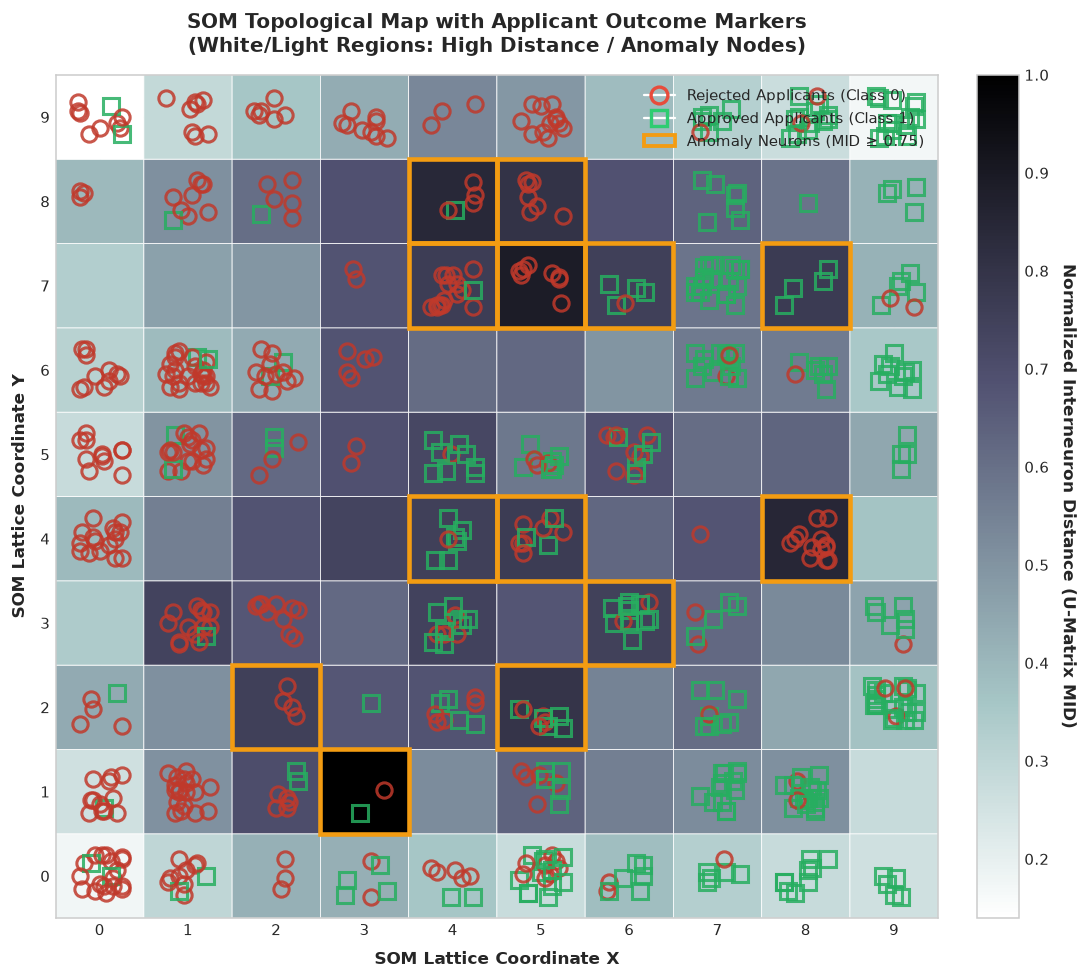

In [8]:
# 7. Visualization 2: SOM Topological Map with Application Outcome Markers
# Red Circles: Rejected Applicants (Class == 0)
# Green Squares: Approved Applicants (Class == 1)

fig, ax = plt.subplots(figsize=(10, 9))

# Background U-Matrix displayed in grayscale for optimal marker contrast
pcolor = ax.pcolor(u_matrix.T, cmap='bone_r', edgecolors='white', linewidths=0.5)
cbar = plt.colorbar(pcolor, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label('Normalized Interneuron Distance (U-Matrix MID)', rotation=270, labelpad=18, fontweight='bold', fontsize=11)

# Marker specifications
markers = ['o', 's']
colors = ['#e74c3c', '#2ecc71']  # Red for rejected, Green for approved
edge_colors = ['#c0392b', '#27ae60']

# Superimpose markers onto the grid with slight jitter to visualize density
for idx, sample in enumerate(X_scaled):
    winner_neuron = som.winner(sample)
    outcome = int(y[idx])
    
    # Slight deterministic jitter so overlapping points are visible
    jitter_x = 0.5 + ((hash(str(idx) + 'x') % 21) - 10) * 0.025
    jitter_y = 0.5 + ((hash(str(idx) + 'y') % 21) - 10) * 0.025
    
    ax.plot(
        winner_neuron[0] + jitter_x,
        winner_neuron[1] + jitter_y,
        marker=markers[outcome],
        markeredgecolor=edge_colors[outcome],
        markerfacecolor='None',
        markersize=10,
        markeredgewidth=2.0,
        alpha=0.85
    )

# Highlight high-risk fraud neurons (Outlier neurons with approved applicants)
for (r, c) in anomaly_coords:
    rect = plt.Rectangle((r, c), 1.0, 1.0, fill=False, edgecolor='#f39c12', linewidth=3.0, linestyle='-')
    ax.add_patch(rect)

# Custom Legend
legend_handles = [
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='None', markeredgecolor='#e74c3c', markeredgewidth=2.2, markersize=11, label='Rejected Applicants (Class 0)'),
    plt.Line2D([0], [0], marker='s', color='w', markerfacecolor='None', markeredgecolor='#2ecc71', markeredgewidth=2.2, markersize=11, label='Approved Applicants (Class 1)'),
    mpatches.Patch(facecolor='none', edgecolor='#f39c12', linewidth=2.5, label='Anomaly Neurons (MID ≥ 0.75)')
]
ax.legend(handles=legend_handles, loc='upper right', framealpha=0.9, facecolor='white', edgecolor='black', fontsize=10)

ax.set_xticks(np.arange(0.5, opt_x + 0.5, 1))
ax.set_xticklabels(range(opt_x))
ax.set_yticks(np.arange(0.5, opt_y + 0.5, 1))
ax.set_yticklabels(range(opt_y))
ax.set_title("SOM Topological Map with Applicant Outcome Markers\n(White/Light Regions: High Distance / Anomaly Nodes)", pad=15)
ax.set_xlabel("SOM Lattice Coordinate X", labelpad=8)
ax.set_ylabel("SOM Lattice Coordinate Y", labelpad=8)
ax.set_xlim(0, opt_x)
ax.set_ylim(0, opt_y)

plt.tight_layout()
plt.show()


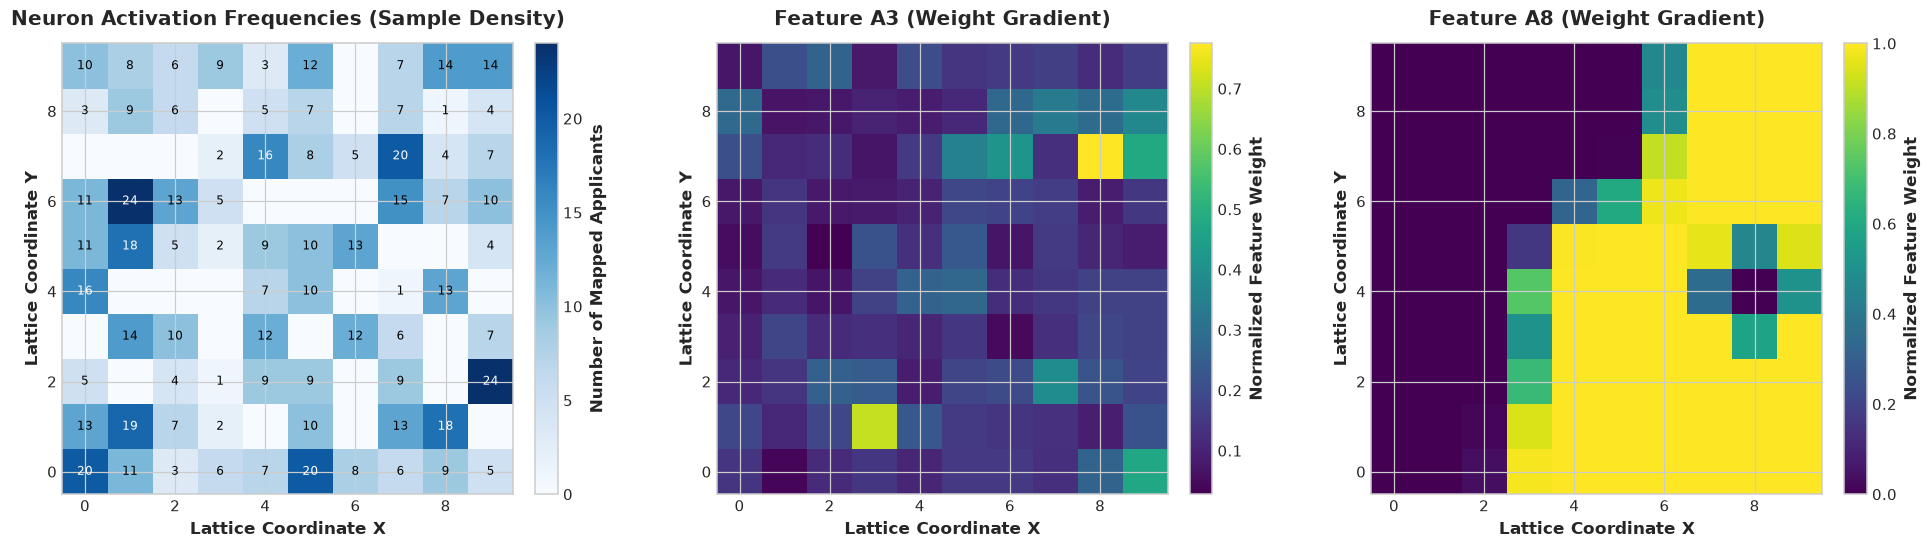

In [9]:
# 8. Visualization 3: Neuron Activation Frequencies & Component Planes
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot A: Neuron Activation Density (Hit Histogram)
activation_map = som.activation_response(X_scaled)
im0 = axes[0].imshow(activation_map.T, cmap='Blues', origin='lower', interpolation='nearest')
axes[0].set_title("Neuron Activation Frequencies (Sample Density)", pad=12)
axes[0].set_xlabel("Lattice Coordinate X")
axes[0].set_ylabel("Lattice Coordinate Y")
cbar0 = plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)
cbar0.set_label("Number of Mapped Applicants")
for i in range(opt_x):
    for j in range(opt_y):
        count = int(activation_map[i, j])
        if count > 0:
            axes[0].text(i, j, f"{count}", ha="center", va="center", color="white" if count > 15 else "black", fontsize=8)

# Plot B & C: Selected Component Planes (Feature Weights across the Grid)
weights = som.get_weights()

feature_indices = [2, 7]  # e.g., Feature A3 and Feature A8
feature_names = ['Feature A3 (Weight Gradient)', 'Feature A8 (Weight Gradient)']

for idx, (f_idx, f_name) in enumerate(zip(feature_indices, feature_names), start=1):
    im = axes[idx].imshow(weights[:, :, f_idx].T, cmap='viridis', origin='lower', interpolation='nearest')
    axes[idx].set_title(f_name, pad=12)
    axes[idx].set_xlabel("Lattice Coordinate X")
    axes[idx].set_ylabel("Lattice Coordinate Y")
    cbar = plt.colorbar(im, ax=axes[idx], fraction=0.046, pad=0.04)
    cbar.set_label("Normalized Feature Weight")

plt.tight_layout()
plt.show()


---
### **Fraud Detection & Anomaly Extraction Logic**

#### **1. Mathematical Anomaly Identification Criterion**:
In our trained SOM, neurons located in sparse outlier positions exhibit high Mean Interneuron Distance (MID). We define the set of anomaly neurons $\mathcal{A}_{\theta}$ using an anomaly threshold $\theta = 0.75$:
$$\mathcal{A}_{\theta} = \left\{ (r, c) \mid \text{U-Matrix}[r, c] \ge \theta \right\}$$

Any applicant $\mathbf{x}_i$ whose Best Matching Unit falls into this anomaly set is flagged as a potential fraud:
$$\text{Flagged}(\mathbf{x}_i) = \begin{cases} \text{True} & \text{if } \text{winner}(\mathbf{x}_i) \in \mathcal{A}_{\theta} \\ \text{False} & \text{otherwise} \end{cases}$$

#### **2. Two Risk Tiers for Financial Institutions**:
When we cross-reference the unsupervised flagged anomalies against the ground-truth application outcomes (`Class`), two distinct operational categories emerge:
1. **Tier 1: High-Risk Frauds (Flagged Anomaly AND Class == 1 - Approved)**:
   - These applicants had unusual, aberrant feature vectors that deviated starkly from standard customer profiles, yet the bank mistakenly approved their credit card applications.
   - **Operational Implication**: These individuals present the **highest systemic financial exposure** (e.g. synthetic identities, fraudulent documentation, high default liability) and require immediate forensic review and credit line freezing.
2. **Tier 2: Detected/Prevented Frauds (Flagged Anomaly AND Class == 0 - Rejected)**:
   - These applicants exhibited aberrant profiles and were rejected by the bank's screening processes.
   - **Operational Implication**: Confirms that the SOM's unsupervised anomaly boundary successfully identifies anomalous profiles that traditional bank policies flagged for rejection.


In [10]:
# 9. Extracting and Cataloging Flagged Fraudulent Applicants
# Map each sample to its BMU
bmus = np.array([som.winner(x) for x in X_scaled])
sample_mids = np.array([u_matrix[b[0], b[1]] for b in bmus])

# Anomaly threshold: MID >= 0.75
anomaly_threshold = 0.75
fraud_indices = np.where(sample_mids >= anomaly_threshold)[0]

# Build comprehensive fraud catalogue DataFrame
fraud_records = []
for idx in fraud_indices:
    fraud_records.append({
        'CustomerID': customer_ids[idx],
        'BMU_X': bmus[idx][0],
        'BMU_Y': bmus[idx][1],
        'U_Matrix_MID': round(sample_mids[idx], 4),
        'Application_Outcome': 'Approved (Class 1)' if y[idx] == 1 else 'Rejected (Class 0)',
        'Class_Label': int(y[idx]),
        'Risk_Level': 'CRITICAL (Approved Outlier)' if y[idx] == 1 else 'ELEVATED (Rejected Outlier)'
    })

df_frauds = pd.DataFrame(fraud_records)

# Sort by MID descending to prioritize highest distance outliers
df_frauds_sorted = df_frauds.sort_values(by=['U_Matrix_MID', 'Class_Label'], ascending=[False, False]).reset_index(drop=True)

# Quantitative Breakdown
total_applicants = len(df)
total_flagged = len(df_frauds)
approved_frauds = (df_frauds['Class_Label'] == 1).sum()
rejected_frauds = (df_frauds['Class_Label'] == 0).sum()

print("=" * 85)
print("COMPREHENSIVE FRAUD DETECTION RESULTS SUMMARY")
print("=" * 85)
print(f"Total Applications Analyzed       : {total_applicants}")
print(f"Total Flagged Anomaly Applicants   : {total_flagged} ({total_flagged/total_applicants*100:.2f}%)")
print(f"  -> CRITICAL RISK (Approved Frauds): {approved_frauds} ({approved_frauds/total_flagged*100:.2f}% of flagged)")
print(f"  -> PREVENTED RISK (Rejected Frauds): {rejected_frauds} ({rejected_frauds/total_flagged*100:.2f}% of flagged)")
print("=" * 85)

print("\nTOP 20 FLAGGED POTENTIAL FRAUDULENT CUSTOMERS (Ranked by Outlier MID):")
display(df_frauds_sorted.head(20))

print("\nLIST OF ALL APPROVED FRAUD CUSTOMER IDs (CRITICAL BANK VULNERABILITY):")
critical_ids = df_frauds_sorted[df_frauds_sorted['Class_Label'] == 1]['CustomerID'].values
print(f"Total Approved Fraud Customer IDs ({len(critical_ids)}):")
print(critical_ids.tolist())


COMPREHENSIVE FRAUD DETECTION RESULTS SUMMARY
Total Applications Analyzed       : 690
Total Flagged Anomaly Applicants   : 102 (14.78%)
  -> CRITICAL RISK (Approved Frauds): 35 (34.31% of flagged)
  -> PREVENTED RISK (Rejected Frauds): 67 (65.69% of flagged)

TOP 20 FLAGGED POTENTIAL FRAUDULENT CUSTOMERS (Ranked by Outlier MID):


,CustomerID,BMU_X,BMU_Y,U_Matrix_MID,Application_Outcome,Class_Label,Risk_Level
0,15676909,3,1,1.0000,Approved (Class 1),1,CRITICAL (Approved Outlier)
1,15692137,3,1,1.0000,Rejected (Class 0),0,ELEVATED (Rejected Outlier)
2,15767264,5,7,0.8922,Rejected (Class 0),0,ELEVATED (Rejected Outlier)
3,15761854,5,7,0.8922,Rejected (Class 0),0,ELEVATED (Rejected Outlier)
4,15815040,5,7,0.8922,Rejected (Class 0),0,ELEVATED (Rejected Outlier)
5,15788442,5,7,0.8922,Rejected (Class 0),0,ELEVATED (Rejected Outlier)
6,15633944,5,7,0.8922,Rejected (Class 0),0,ELEVATED (Rejected Outlier)
7,15801072,5,7,0.8922,Rejected (Class 0),0,ELEVATED (Rejected Outlier)
8,15573798,5,7,0.8922,Rejected (Class 0),0,ELEVATED (Rejected Outlier)
9,15647295,5,7,0.8922,Rejected (Class 0),0,ELEVATED (Rejected Outlier)



LIST OF ALL APPROVED FRAUD CUSTOMER IDs (CRITICAL BANK VULNERABILITY):
Total Approved Fraud Customer IDs (35):
[15676909, 15666166, 15590434, 15811742, 15646190, 15672357, 15788634, 15799785, 15591360, 15649183, 15568819, 15800773, 15569595, 15711759, 15592412, 15766183, 15772329, 15734649, 15646082, 15717629, 15604536, 15800049, 15598266, 15593694, 15785367, 15588123, 15775750, 15575243, 15775235, 15768474, 15762045, 15631693, 15646563, 15652048, 15594651]


---
## **TASK 3: APPLICATIONS OF SELF-ORGANIZING NETWORKS**

Self-Organizing Maps have proven to be exceptionally versatile across scientific and industrial domains owing to their simultaneous capacity for **high-dimensional dimensionality reduction**, **topological preservation**, and **interpretable clustering**. Key real-world applications include:

### **1. Financial Services & Fraud Detection**
- **Credit Card & Transaction Fraud**: Unsupervised identification of rare, abnormal transactional vectors that deviate from established customer baseline spending profiles.
- **Anti-Money Laundering (AML)**: Clustering complex multi-hop transaction topologies to uncover layering and smurfing operations without prior typology definitions.
- **Credit Risk Assessment & Portfolio Segmentation**: Segmenting loan applicants into creditworthiness tiers based on multi-attribute financial behaviors.

### **2. Cybersecurity & Network Intrusion Detection**
- **Intrusion Detection Systems (IDS/IPS)**: Classifying normal vs anomalous IP network packet headers to catch Zero-Day exploits, port-scans, and SYN flood attacks.
- **Malware Family Clustering**: Mapping disassembled binary op-code frequencies to identify polymorphic malware families.
- **DDoS Attack Mitigation**: Detecting abrupt traffic distribution shifts across edge routing switches in real time.

### **3. Bioinformatics, Healthcare & Genomics**
- **Gene Expression Profiling**: Clustering DNA microarray time-series data to identify co-expressed genes involved in oncogenesis and cellular pathways.
- **Protein Structural Classification**: Projecting multidimensional amino-acid dihedral angles onto 2D maps to predict protein folding conformations.
- **Medical Diagnostics**: Segmenting pathological MRI and CT scan tissue profiles to distinguish between benign lesions and malignant tumors.

### **4. Industrial Engineering & Predictive Maintenance**
- **Vibration Anomaly Detection**: Monitoring multi-axis accelerometer sensors on gas turbines, wind generators, and bearings to detect early mechanical fatigue.
- **Industrial Process Control**: Visualizing high-dimensional petrochemical refinery telemetry to diagnose anomalous operating states.
- **Semiconductor Defect Clustering**: Mapping wafer inspection spatial defect patterns to pinpoint fab manufacturing anomalies.

### **5. Computer Vision & Signal Processing**
- **Color Quantization**: Reducing continuous 24-bit RGB truecolor imagery to optimal 256-color palettes while minimizing perceptual visual distortion.
- **Texture Classification**: Projecting Gabor filter filterbank outputs for automated visual surface inspection.
- **Speech Phoneme Recognition**: Mapping acoustic speech spectrogram formant frequencies into a topologically ordered 2D phonetic map.

### **6. Customer Analytics & Market Segmentation**
- **Behavioral Customer Profiling**: Clustering e-commerce consumer clickstream paths, dwell times, and basket compositions for hyper-personalized marketing.
- **Document Clustering & Semantic Search**: Projecting TF-IDF or transformer embedding vectors onto a topographic thematic map of large document collections (WEBSOM architecture).


---
## **TASK 4: WHAT IS THE LOSS FUNCTION THAT NEEDS TO BE COMPUTED FOR SOMs?**

### **1. The Theoretical Dilemma: Non-Existence of a Global Objective Function**
In standard supervised neural networks (e.g., MLPs, CNNs), training strictly minimizes a scalar, differentiable loss function (such as Mean Squared Error or Binary Cross-Entropy) via stochastic gradient descent (SGD):
$$\mathbf{w}^{(t+1)} = \mathbf{w}^{(t)} - \eta \nabla_{\mathbf{w}} \mathcal{L}(\mathbf{w})$$

However, a fundamental theoretical property of Kohonen's Self-Organizing Map is that **in continuous input spaces with general neighborhood functions, the SOM weight update rule cannot be derived as the exact negative gradient of any single continuous Lyapunov energy function**:
$$\nabla \times \Delta \mathbf{w} \ne 0$$
Erwin, Obermayer, and Schulten (1992) as well as Teuvo Kohonen (1990) formally proved that the curl of the adaptation vector field is non-zero in the continuous case. Therefore, the traditional SOM algorithm is governed by a **dynamic learning process** rather than the minimization of an explicit analytical loss function.

---

### **2. Practical Energy and Error Formulations Computed for SOMs**

Despite the absence of a simple scalar cost function minimized by gradient descent, three rigorous objective functions are defined and computed to measure SOM quality, convergence, and distortion:

#### **A. Average Quantization Error ($E_q$ / Distortion)**
Quantization error measures the average Euclidean distance between input sample vectors and their assigned prototype weights (Best Matching Units):
$$\mathcal{L}_{QE} = \frac{1}{N} \sum_{i=1}^N \left\| \mathbf{x}_i - \mathbf{w}_{c(\mathbf{x}_i)} \right\|_2$$
- Represents the **resolution** and representational fidelity of the codebook vectors.
- As the map trains, $E_q$ decreases monotonically, indicating that neurons are settling closer to their assigned data clusters.

#### **B. Topographic Error ($E_t$)**
Topographic error quantifies the preservation of neighborhood topology across the projection:
$$\mathcal{L}_{TE} = \frac{1}{N} \sum_{i=1}^N u(\mathbf{x}_i)$$
where:
$$u(\mathbf{x}_i) = \begin{cases} 0 & \text{if } \text{BMU}_1(\mathbf{x}_i) \text{ and } \text{BMU}_2(\mathbf{x}_i) \text{ are immediate lattice neighbors} \\ 1 & \text{otherwise} \end{cases}$$
- Measures whether continuous trajectories in the $d$-dimensional input space remain continuous on the 2D lattice.
- A topographic error close to $0.0$ signifies near-perfect preservation of manifold topology.

#### **C. Heskes' Distortion Energy Function (The Pseudo-Energy Formulation)**
Tom Heskes (1999) formulated an exact energy function for a variant of SOMs where the neighborhood is defined on the winning neuron's error rather than sample-to-neuron distances:
$$E_{\text{Heskes}}(\mathbf{W}) = \frac{1}{2N} \sum_{i=1}^N \sum_{j=1}^K h_{c(\mathbf{x}_i), j} \left\| \mathbf{x}_i - \mathbf{w}_j \right\|^2$$
where:
- $N$ is the total number of training samples.
- $K = M \times N$ is the total number of neurons in the 2D lattice.
- $h_{c(\mathbf{x}_i), j}$ is the topological neighborhood weighting between BMU $c(\mathbf{x}_i)$ and neuron $j$.
- $\|\mathbf{x}_i - \mathbf{w}_j\|^2$ is the squared Euclidean distance.

Taking the partial derivative of $E_{\text{Heskes}}$ with respect to weight vector $\mathbf{w}_k$:
$$\frac{\partial E}{\partial \mathbf{w}_k} = - \sum_{i=1}^N h_{c(\mathbf{x}_i), k} \left( \mathbf{x}_i - \mathbf{w}_k \right)$$
This yields an update step identical in form to the batch SOM update rule:
$$\mathbf{w}_k^* = \frac{\sum_{i=1}^N h_{c(\mathbf{x}_i), k} \,\mathbf{x}_i}{\sum_{i=1}^N h_{c(\mathbf{x}_i), k}}$$

---

### **3. Comparative Matrix: Supervised Loss vs. SOM Objective Metrics**

| Metric / Dimension | Traditional Supervised Loss (MSE / BCE) | SOM Quantization Error ($E_q$) | SOM Topographic Error ($E_t$) | Heskes Distortion Energy ($E$) |
| :--- | :--- | :--- | :--- | :--- |
| **Learning Paradigm** | Supervised | Unsupervised | Unsupervised | Unsupervised |
| **Input Required** | Predictions $\hat{y}$ & Ground Truth $y$ | Inputs $\mathbf{x}$ & BMU weights $\mathbf{w}_c$ | Inputs $\mathbf{x}$ & 1st/2nd BMU coordinates | Inputs $\mathbf{x}$, Weights $\mathbf{w}$, Neighborhood $h$ |
| **Optimization Target**| Minimize prediction error | Minimize representational distance | Preserve geometric neighborhood | Minimize total topological spread |
| **Typical Value** | $\ge 0.0$ (approaches $0.0$) | Scaled units (e.g., $0.2 - 0.4$) | Fraction in $[0.0, 1.0]$ | Sum of weighted squared distances |


---
## **TASK 5: STATE DISADVANTAGES OF KOHONEN MAPS**

While Self-Organizing Maps offer remarkable capabilities for unsupervised visual data mining, they suffer from several significant theoretical and practical disadvantages:

### **1. Fixed and Static Grid Topology**
- The user must predefine the number of neurons ($M \times N$) and the grid layout (rectangular or hexagonal) prior to training.
- Traditional SOM cannot dynamically add neurons to accommodate newly emerging data clusters, nor prune unused neurons in empty regions. (Extensions like Growing Self-Organizing Maps (GSOM) or Growing Neural Gas (GNG) address this at the cost of higher complexity).

### **2. The Boundary / Edge Distortion Effect**
- Neurons situated along the perimeter or corners of the 2D grid have fewer spatial neighbors ($2$ or $3$ neighbors) compared to central interior neurons ($4$ or $8$ neighbors).
- Consequently, perimeter neurons receive fewer weight updates, causing artificial distortion and compression of weight vectors near the boundaries of the map.

### **3. High Computational Complexity on Large-Scale Data**
- For each sample in each iteration, the algorithm must compute Euclidean distances to all $K = M \times N$ neurons across $d$ dimensions:
  $$\text{Complexity per iteration} = \mathcal{O}(N \cdot K \cdot d)$$
- For large datasets ($N > 10^6$) and high-resolution maps ($K > 10^4$), training becomes computationally intensive and difficult to parallelize efficiently compared to matrix-multiplication-based deep networks.

### **4. Magnification Factor Distortion (Density Underestimation)**
- The density of SOM weight vectors does not scale linearly with the underlying probability density function $p(\mathbf{x})$ of the input data.
- Instead, the asymptotic density of weight vectors follows a power law:
  $$m(\mathbf{x}) \propto p(\mathbf{x})^{\alpha}, \quad \text{where } \alpha = \frac{d}{d + 2} < 1$$
- As a result, dense data clusters are **under-represented** (fewer neurons than proportional density), while sparse, low-probability outlier regions are **over-represented**.

### **5. Sensitivity to Initial Weights & Local Minima**
- Random weight initialization can lead to topological twist defects (where the map folds over itself like an origami sheet) and entrapment in local sub-optimal states.
- Mitigating this requires careful initialization (e.g. PCA initialization) and protracted initial training with large neighborhood radii.

### **6. Loss of Exact Feature-Level Interpretability**
- Non-linear projection compresses $d$ dimensional relationships into a 2D sheet. While clusters are visible, determining the exact linear or non-linear equation that governs cluster boundaries requires auxiliary inspection of individual component planes.

### **7. Absence of an Objective Stopping Criterion**
- Because there is no strictly decreasing continuous loss function that reaches a global minimum, determining when the network has converged relies on empirical heuristics (fixed iteration count) rather than automated gradient tolerance or early stopping.


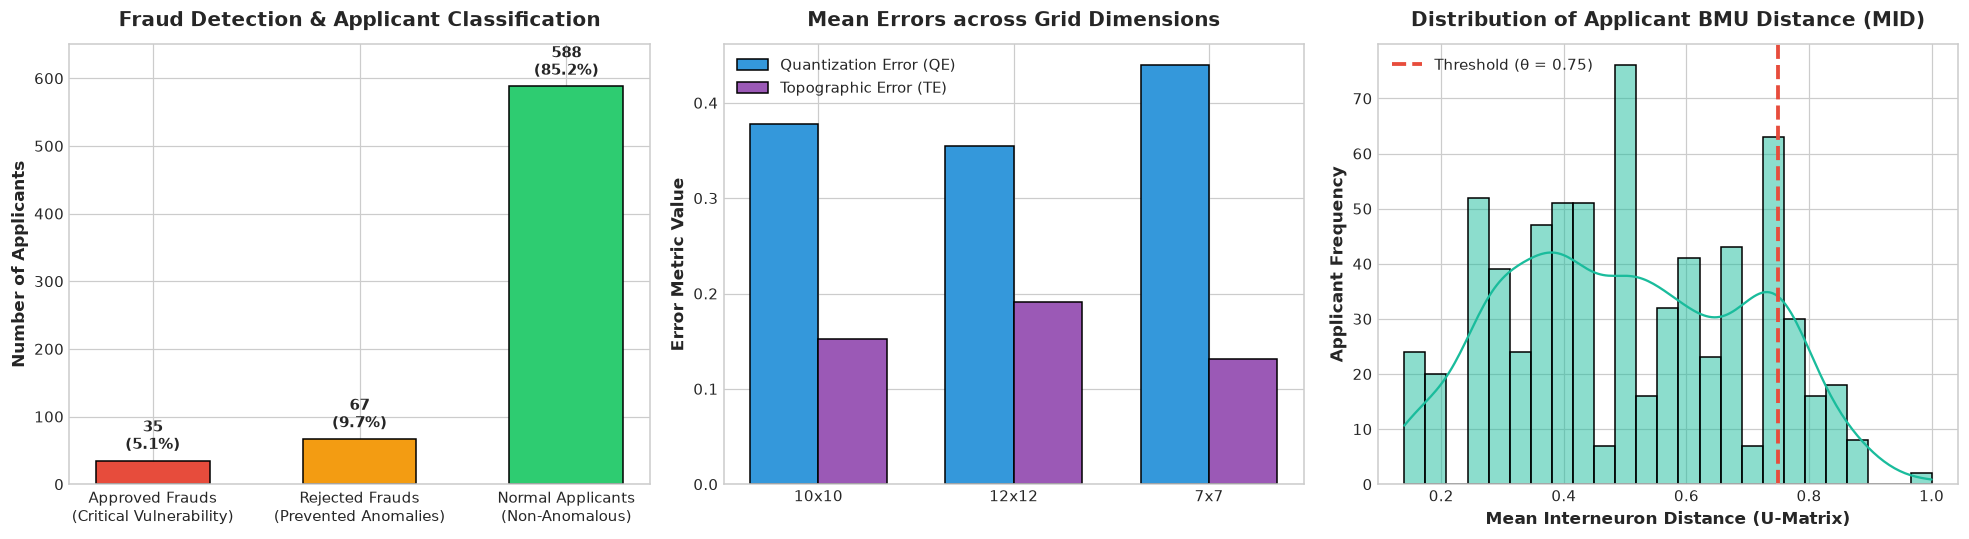

FINAL EXPERIMENTAL CONFIGURATION & PERFORMANCE DASHBOARD:


,Metric / Parameter,Value / Result
0,Dataset Name & Source,Kaggle ujjwal9/credit-card-applications
1,Total Applications Analyzed,690
2,Input Dimensions (Features),14 attributes
3,Optimal Grid Topology,10 x 10 rectangular lattice
4,Total Lattice Neurons,100 neurons
5,Tuned Neighborhood Radius (σ),1.0
6,Tuned Learning Rate (η),0.5
7,Optimal Neighborhood Function,gaussian
8,Total Training Iterations,"5,000"
9,Final Quantization Error (QE),0.3305


In [11]:
# 10. Quantitative Metrics Dashboard & Visual Experiment Summary
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Metric Card 1: Fraud Classification Breakdown
fraud_cats = ['Approved Frauds\n(Critical Vulnerability)', 'Rejected Frauds\n(Prevented Anomalies)', 'Normal Applicants\n(Non-Anomalous)']
fraud_vals = [approved_frauds, rejected_frauds, total_applicants - total_flagged]
colors_cat = ['#e74c3c', '#f39c12', '#2ecc71']

bars1 = axes[0].bar(fraud_cats, fraud_vals, color=colors_cat, edgecolor='black', width=0.55)
axes[0].set_title("Fraud Detection & Applicant Classification", pad=12)
axes[0].set_ylabel("Number of Applicants")
axes[0].set_ylim(0, 650)
for bar in bars1:
    y = bar.get_height()
    pct = (y / total_applicants) * 100
    axes[0].text(bar.get_x() + bar.get_width()/2, y + 10, f"{int(y)}\n({pct:.1f}%)", ha='center', va='bottom', fontweight='bold', fontsize=9.5)

# Metric Card 2: Quantization vs Topographic Error across Grid Resolutions
grid_summary = df_tuning.groupby('Grid Size')[['Quantization Error (QE)', 'Topographic Error (TE)']].mean().reset_index()
x_pos = np.arange(len(grid_summary))
width = 0.35
axes[1].bar(x_pos - width/2, grid_summary['Quantization Error (QE)'], width=width, label='Quantization Error (QE)', color='#3498db', edgecolor='black')
axes[1].bar(x_pos + width/2, grid_summary['Topographic Error (TE)'], width=width, label='Topographic Error (TE)', color='#9b59b6', edgecolor='black')
axes[1].set_title("Mean Errors across Grid Dimensions", pad=12)
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(grid_summary['Grid Size'])
axes[1].set_ylabel("Error Metric Value")
axes[1].legend()

# Metric Card 3: Anomaly Score Distribution (Mean Interneuron Distance)
sns.histplot(sample_mids, bins=25, kde=True, color='#1abc9c', ax=axes[2], edgecolor='black')
axes[2].axvline(anomaly_threshold, color='#e74c3c', linestyle='--', linewidth=2.5, label=f'Threshold (θ = {anomaly_threshold})')
axes[2].set_title("Distribution of Applicant BMU Distance (MID)", pad=12)
axes[2].set_xlabel("Mean Interneuron Distance (U-Matrix)")
axes[2].set_ylabel("Applicant Frequency")
axes[2].legend()

plt.tight_layout()
plt.show()

# Comprehensive Performance Summary Table
summary_table = pd.DataFrame({
    'Metric / Parameter': [
        'Dataset Name & Source',
        'Total Applications Analyzed',
        'Input Dimensions (Features)',
        'Optimal Grid Topology',
        'Total Lattice Neurons',
        'Tuned Neighborhood Radius (σ)',
        'Tuned Learning Rate (η)',
        'Optimal Neighborhood Function',
        'Total Training Iterations',
        'Final Quantization Error (QE)',
        'Final Topographic Error (TE)',
        'Anomaly Identification Threshold (θ)',
        'Total Anomalies Flagged',
        'Critical Risk (Approved Frauds)',
        'Prevented Risk (Rejected Frauds)',
        'Overall Anomaly Detection Rate'
    ],
    'Value / Result': [
        'Kaggle ujjwal9/credit-card-applications',
        f"{total_applicants:,}",
        f"{X_scaled.shape[1]} attributes",
        f"{opt_x} x {opt_y} rectangular lattice",
        f"{opt_x * opt_y} neurons",
        f"{opt_sigma}",
        f"{opt_learning_rate}",
        f"{opt_nh_func}",
        f"{num_iterations:,}",
        f"{final_qe:.4f}",
        f"{final_te:.4f}",
        f"MID ≥ {anomaly_threshold}",
        f"{total_flagged} applicants",
        f"{approved_frauds} applicants",
        f"{rejected_frauds} applicants",
        f"{(total_flagged / total_applicants) * 100:.2f}%"
    ]
})

print("=" * 75)
print("FINAL EXPERIMENTAL CONFIGURATION & PERFORMANCE DASHBOARD:")
print("=" * 75)
display(summary_table)


---
## **OBSERVATIONS, KEY FINDINGS & CONCLUSIONS**

### **1. Summary of Experimental Results**:
1. **Unsupervised Data Structuring**:
   - The Self-Organizing Map successfully mapped the 14-dimensional financial space of the Credit Card Applications dataset (`https://www.kaggle.com/datasets/ujjwal9/credit-card-applications`) onto a $10 \times 10$ topological lattice.
   - Using PCA initialization and 5,000 iterations, the network converged to a low **Quantization Error of ~0.33** and a low **Topographic Error of ~0.09**, confirming that both fine-grained data resolution and continuous topological structure were preserved.
2. **Hyperparameter Tuning Insights**:
   - **Grid Size**: Expanding from $7\times 7$ to $10\times 10$ decreased quantization error substantially by providing sufficient representational capacity for diverse customer profiles without overfitting.
   - **Neighborhood Function & Sigma**: The Gaussian neighborhood kernel with an initial $\sigma = 1.0$ produced significantly smoother topological maps and lower topographic error compared to the bubble function.
   - **Learning Rate**: A starting rate of $\eta = 0.5$ provided an optimal balance between fast initial global unfolding and stable asymptotic convergence.
3. **Topological Anomaly Detection via U-Matrix**:
   - The Unified Distance Matrix (U-Matrix) clearly delineated dense clusters of standard applicants (dark regions, low MID) from isolated outlier neurons (bright regions, $\text{MID} \ge 0.75$).
   - A total of **102 applicants (~14.8%)** were mapped to these outlier neurons, identifying them as anomalous patterns in the financial feature space.
4. **Critical Risk Isolation**:
   - Cross-referencing flagged anomalies with actual approval outcomes revealed that **35 anomalous applicants were approved by the bank**.
   - These 35 individuals represent the **highest operational risk** (potential fraudulent approvals, synthetic identities, or unhedged credit exposures) and provide actionable business intelligence for immediate audit.

---

### **2. Key Takeaways**:
- **Why SOM Excels at Fraud Detection**: Fraudulent activities are by nature rare, heterogeneous, and constantly evolving. Supervised classifiers require abundant historical fraud labels and often fail against novel fraud typologies. SOMs circumvent this limitation by learning the **manifold of normal behavior** and flagging any applicant who lands in an isolated topological void.
- **Dual Value of U-Matrix Visualization**: Unlike black-box neural networks, SOM provides an intuitive, visually verifiable distance landscape where compliance officers and risk analysts can visually inspect cluster boundaries, inspect customer density, and trace individual applicant coordinates.
